# 01 · Exploratory Data Analysis: PathSnap
**Owner:** Patil · **Partitions used:** `train` (80 trips) and `student_test` (10 trips). The evaluator partition is never touched.

Goals (from the *Dataset Exploration* guide):
1. Inventory: trips, files, rows, sizes
2. Missing / invalid GPS observations, timestamp ordering and gaps
3. Speeds and jumps, geographical extent
4. Road-network size, direction (reverse twins), connectivity, isolated nodes
5. Reference-route structure and continuity
6. Anomalies, a Folium map, and data-quality notes

In [1]:
import os, sys
# run from the repository root regardless of where the notebook lives
_p = os.path.abspath(os.getcwd())
while not os.path.isdir(os.path.join(_p, "pathsnap")):
    _p = os.path.dirname(_p)
os.chdir(_p); sys.path.insert(0, _p)
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110
print("repo root:", os.getcwd())
import networkx as nx, folium
ROOT = os.path.join("data", "raw")
OUT = os.path.join("results", "eda"); os.makedirs(OUT, exist_ok=True)
os.makedirs(os.path.join("results", "maps"), exist_ok=True)

def load_trip(split, trip):
    d = os.path.join(ROOT, split, trip)
    track = pd.read_csv(f"{d}/{trip}.track", sep=r"\s+", header=None, names=["lon", "lat", "t"])
    nodes = pd.read_csv(f"{d}/{trip}.nodes", sep=r"\s+", header=None, names=["lon", "lat"])
    arcs  = pd.read_csv(f"{d}/{trip}.arcs",  sep=r"\s+", header=None, names=["u", "v"])
    route = pd.read_csv(f"{d}/{trip}.route", header=None, names=["arc_id"])
    return track, nodes, arcs, route

def haversine_m(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, (lon1, lat1, lon2, lat2))
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 2 * 6371000 * np.arcsin(np.sqrt(a))

trips = [(s, t) for s in ["train", "student_test"] for t in sorted(os.listdir(f"{ROOT}/{s}"))]
print(len(trips), "trips")

repo root: C:\Users\shrey\OneDrive\Documents\ML Hackathon\PathSnap_7_H


90 trips


## 1. Inventory: trips, files, rows, sizes

In [2]:
inv = []
for split, trip in trips:
    d = os.path.join(ROOT, split, trip)
    row = dict(split=split, trip=trip, n_files=len(os.listdir(d)))
    for ext in ["track", "nodes", "arcs", "route"]:
        p = f"{d}/{trip}.{ext}"
        row[f"has_{ext}"] = os.path.exists(p)
        row[f"{ext}_kb"] = round(os.path.getsize(p) / 1024, 1) if os.path.exists(p) else np.nan
    inv.append(row)
inv = pd.DataFrame(inv); inv.to_csv(f"{OUT}/inventory.csv", index=False)
display(inv.groupby("split").agg(trips=("trip", "count"), files_per_trip=("n_files", "mean"),
        all_have_route=("has_route", "all"), total_MB=("arcs_kb", lambda s: round((s.sum() + inv.loc[s.index, ["track_kb","nodes_kb","route_kb"]].sum().sum())/1024, 1))))
inv.head()

,trips,files_per_trip,all_have_route,total_MB
split,,,,
student_test,10,4.0,True,4.2
train,80,4.0,True,85.6


,split,trip,n_files,has_track,track_kb,has_nodes,nodes_kb,has_arcs,arcs_kb,has_route,route_kb
0,train,00000001,4,True,40.0,True,1647.8,True,1902.8,True,3.0
1,train,00000002,4,True,232.5,True,155.0,True,152.9,True,1.4
2,train,00000003,4,True,25.6,True,178.5,True,171.6,True,0.4
3,train,00000004,4,True,34.2,True,143.6,True,146.2,True,1.5
4,train,00000005,4,True,32.6,True,17.5,True,12.1,True,0.4


Every trip folder has exactly 4 files (`.track`, `.nodes`, `.arcs`, `.route`). Each trip carries **its own local road network**: there is no shared global map.

## 2. Per-trip statistics (GPS, timing, speed, network, connectivity, route)

In [3]:
rows = []
dts_all, speeds_all = {}, {}
for split, trip in trips:
    track, nodes, arcs, route = load_trip(split, trip)
    dt = track.t.diff().dropna()
    step = haversine_m(track.lon.values[:-1], track.lat.values[:-1], track.lon.values[1:], track.lat.values[1:])
    speed = step / np.maximum(dt.values, 1e-9)
    dts_all[trip], speeds_all[trip] = dt.values, speed
    pairs = set(zip(arcs.u, arcs.v))
    G = nx.DiGraph(); G.add_nodes_from(range(len(nodes))); G.add_edges_from(pairs)
    r = route.arc_id.values
    rows.append(dict(
        split=split, trip=trip, n_points=len(track), n_nodes=len(nodes), n_arcs=len(arcs), n_route_arcs=len(r),
        duration_min=(track.t.iloc[-1] - track.t.iloc[0]) / 60,
        n_nan=int(track.isna().sum().sum()), n_dup_rows=int(track.duplicated().sum()),
        n_invalid_coord=int(((track.lat.abs() > 90) | (track.lon.abs() > 180) | ((track.lat == 0) & (track.lon == 0))).sum()),
        t_sorted=bool(track.t.is_monotonic_increasing), pct_dt_1s=float((dt == 1).mean()),
        gaps_over_5s=int((dt > 5).sum()), gaps_over_30s=int((dt > 30).sum()), max_gap_s=float(dt.max()),
        median_speed_mps=float(np.median(speed)), p99_speed_mps=float(np.percentile(speed, 99)),
        jumps_over_70mps=int((speed > 70).sum()),
        path_km=float(step.sum() / 1000),
        lon_c=track.lon.mean(), lat_c=track.lat.mean(),
        extent_km_x=float(haversine_m(track.lon.min(), track.lat.mean(), track.lon.max(), track.lat.mean()) / 1000),
        extent_km_y=float(haversine_m(track.lon.mean(), track.lat.min(), track.lon.mean(), track.lat.max()) / 1000),
        pct_arcs_with_reverse=float(np.mean([(v, u) in pairs for u, v in pairs])),
        n_weak_components=nx.number_weakly_connected_components(G),
        largest_wcc_frac=max(len(c) for c in nx.weakly_connected_components(G)) / len(nodes),
        n_isolated_nodes=nx.number_of_isolates(G),
        route_breaks=int(np.sum(arcs.v.values[r[:-1]] != arcs.u.values[r[1:]])),
        route_unique_frac=len(set(r)) / len(r),
    ))
stats = pd.DataFrame(rows); stats.to_csv(f"{OUT}/trip_stats.csv", index=False)
stats.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
n_points,90.0,2528.633,3157.000,262.000,899.250,1496.500,2816.250,19313.000
n_nodes,90.0,22490.822,30868.526,299.000,3655.250,9305.000,26296.500,155003.000
n_arcs,90.0,45132.722,61920.285,649.000,7282.750,18761.500,52913.250,307392.000
n_route_arcs,90.0,386.811,359.238,59.000,166.750,272.500,464.250,2266.000
duration_min,90.0,87.904,287.334,4.417,18.897,28.500,60.312,2567.167
n_nan,90.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
n_dup_rows,90.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
n_invalid_coord,90.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
pct_dt_1s,90.0,0.943,0.112,0.531,0.964,0.991,1.000,1.000
gaps_over_5s,90.0,14.000,40.236,0.000,0.000,1.000,10.000,320.000


## 3. Data types, missing and invalid values

In [4]:
t0, n0, a0, r0 = load_trip("train", stats.trip.iloc[0])
display(pd.DataFrame({"file": [".track", ".nodes", ".arcs", ".route"],
                      "columns": [list(t0.columns), list(n0.columns), list(a0.columns), list(r0.columns)],
                      "dtypes": [list(map(str, t0.dtypes)), list(map(str, n0.dtypes)), list(map(str, a0.dtypes)), list(map(str, r0.dtypes))]}))
mv = stats.groupby("split")[["n_nan", "n_dup_rows", "n_invalid_coord"]].sum()
mv["timestamps_sorted_all_trips"] = stats.groupby("split").t_sorted.all()
mv

,file,columns,dtypes
0,.track,"[lon, lat, t]","[float64, float64, float64]"
1,.nodes,"[lon, lat]","[float64, float64]"
2,.arcs,"[u, v]","[int64, int64]"
3,.route,[arc_id],[int64]


,n_nan,n_dup_rows,n_invalid_coord,timestamps_sorted_all_trips
split,,,,
student_test,0,0,0,True
train,0,0,0,True


**No NaNs, duplicates or invalid coordinates** in either partition, and timestamps are sorted in every trip. The pipeline still defensively drops NaN rows, sorts by time and removes duplicate timestamps (`pathsnap/io.py`).

## 4. Trajectory length and sampling

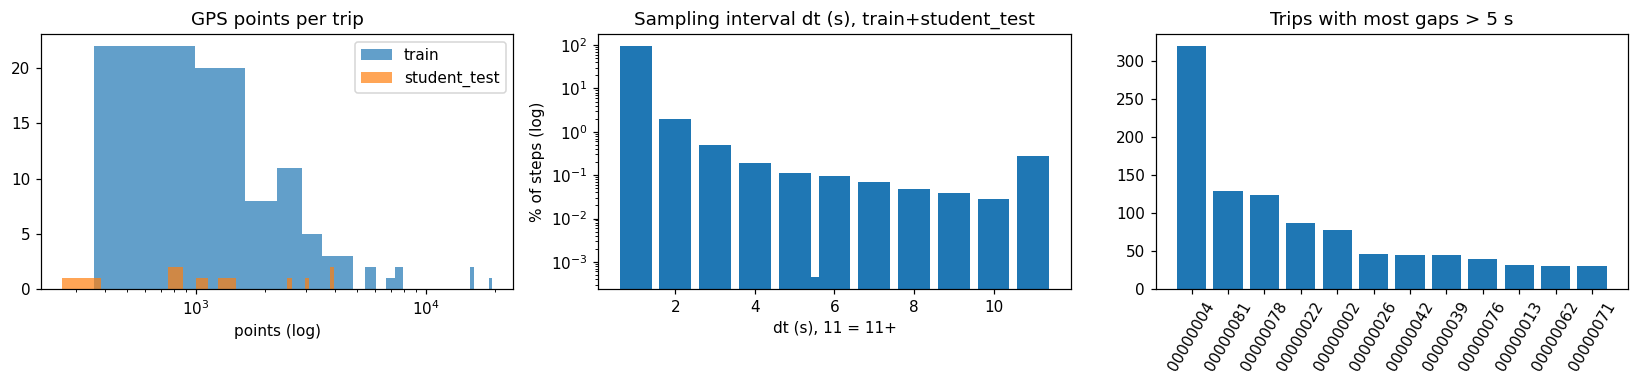

steps exactly 1 s: 96.68% | gaps > 5 s: 1260 | gaps > 30 s: 135 | max gap: 153064 s
points per trip: {'min': 262.0, '50%': 1496.5, 'max': 19313.0}


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for s, c in [("train", "C0"), ("student_test", "C1")]:
    ax[0].hist(stats[stats.split == s].n_points, bins=30, alpha=.7, label=s, color=c)
ax[0].set_xscale("log"); ax[0].set_title("GPS points per trip"); ax[0].set_xlabel("points (log)"); ax[0].legend()
dt_all = np.concatenate(list(dts_all.values()))
vals, cnts = np.unique(np.clip(dt_all, 0, 11), return_counts=True)
ax[1].bar(vals, cnts / cnts.sum() * 100); ax[1].set_yscale("log")
ax[1].set_title("Sampling interval dt (s), train+student_test"); ax[1].set_xlabel("dt (s), 11 = 11+"); ax[1].set_ylabel("% of steps (log)")
top = stats.sort_values("gaps_over_5s", ascending=False).head(12)
ax[2].bar(top.trip, top.gaps_over_5s); ax[2].set_title("Trips with most gaps > 5 s"); ax[2].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.savefig(f"{OUT}/sampling.png"); plt.show()
print(f"steps exactly 1 s: {np.mean(dt_all == 1):.2%} | gaps > 5 s: {(dt_all > 5).sum()} | gaps > 30 s: {(dt_all > 30).sum()} | max gap: {dt_all.max():.0f} s")
print("points per trip:", stats.n_points.describe()[["min", "50%", "max"]].to_dict())

## 5. Speeds and jumps

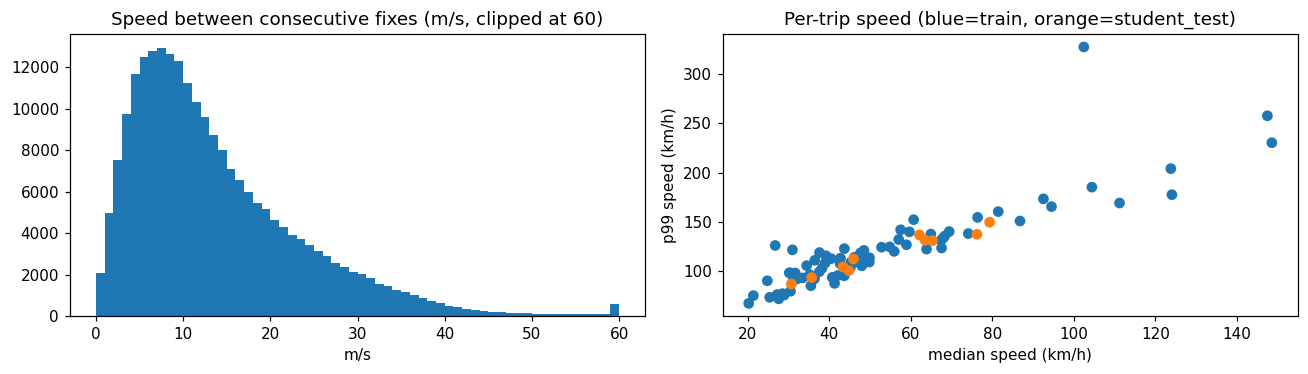

median speed 40.7 km/h, p99 163.9 km/h, jumps > 70 m/s: 148


In [6]:
sp = np.concatenate(list(speeds_all.values()))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(np.clip(sp, 0, 60), bins=60); ax[0].set_title("Speed between consecutive fixes (m/s, clipped at 60)"); ax[0].set_xlabel("m/s")
ax[1].scatter(stats.median_speed_mps * 3.6, stats.p99_speed_mps * 3.6, c=(stats.split == "train").map({True: "C0", False: "C1"}))
ax[1].set_xlabel("median speed (km/h)"); ax[1].set_ylabel("p99 speed (km/h)"); ax[1].set_title("Per-trip speed (blue=train, orange=student_test)")
plt.tight_layout(); plt.savefig(f"{OUT}/speed.png"); plt.show()
print(f"median speed {np.median(sp)*3.6:.1f} km/h, p99 {np.percentile(sp,99)*3.6:.1f} km/h, jumps > 70 m/s: {(sp>70).sum()}")

## 6. Geographical extent: the trips are worldwide

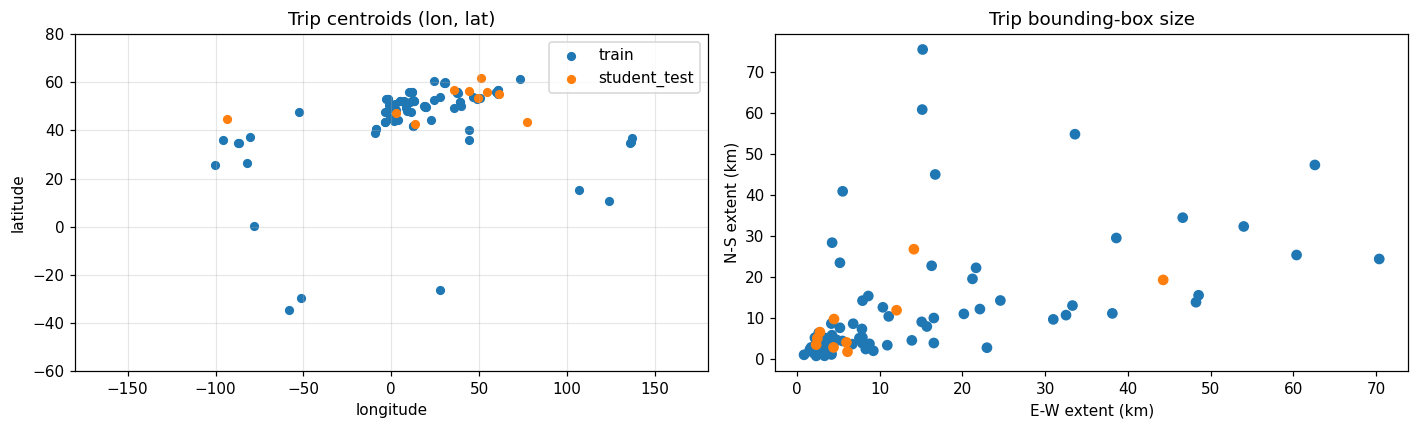

lon range -100.3 to 137.2 | lat range -34.6 to 61.7
max trip extent (km): {'extent_km_x': 70.4, 'extent_km_y': 75.4}


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for s, c in [("train", "C0"), ("student_test", "C1")]:
    d = stats[stats.split == s]; ax[0].scatter(d.lon_c, d.lat_c, s=25, c=c, label=s)
ax[0].set_xlim(-180, 180); ax[0].set_ylim(-60, 80); ax[0].grid(alpha=.3); ax[0].legend()
ax[0].set_title("Trip centroids (lon, lat)"); ax[0].set_xlabel("longitude"); ax[0].set_ylabel("latitude")
ax[1].scatter(stats.extent_km_x, stats.extent_km_y, c=(stats.split == "train").map({True: "C0", False: "C1"}))
ax[1].set_xlabel("E-W extent (km)"); ax[1].set_ylabel("N-S extent (km)"); ax[1].set_title("Trip bounding-box size")
plt.tight_layout(); plt.savefig(f"{OUT}/geography.png"); plt.show()
print("lon range", stats.lon_c.min().round(1), "to", stats.lon_c.max().round(1), "| lat range", stats.lat_c.min().round(1), "to", stats.lat_c.max().round(1))
print("max trip extent (km):", stats[["extent_km_x", "extent_km_y"]].max().round(1).to_dict())

Trips are spread over several continents but each one spans only a few km to tens of km. **Degrees are not distances**: 1° of longitude is about 111 km at the equator but about 55 km at 60° N. Hence the pipeline uses a **per-trip local metric projection** (`pathsnap/geo.py`), and this notebook uses haversine.

## 7. Road network: size, direction, connectivity

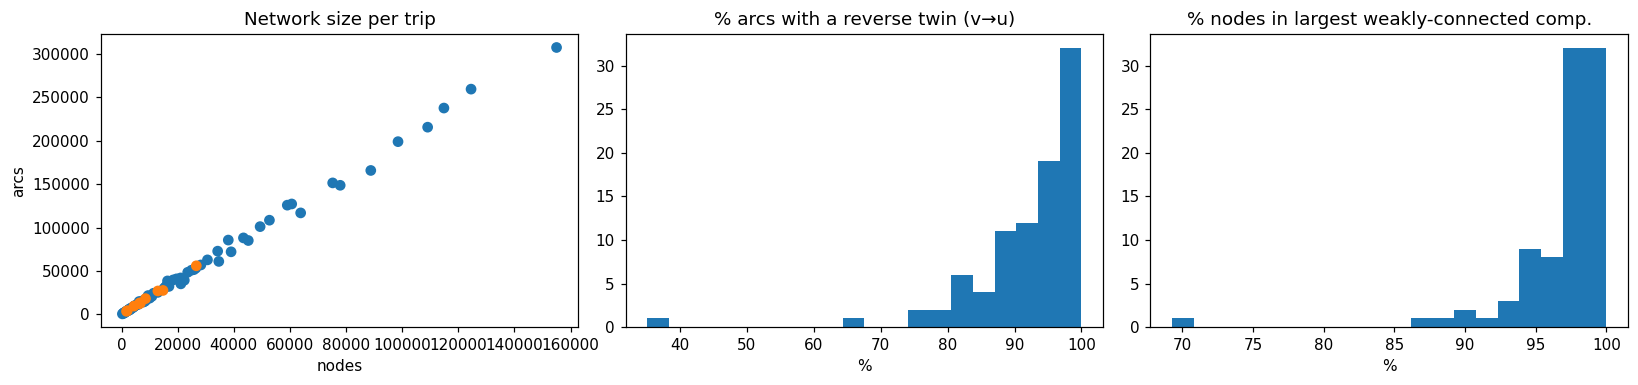

split                        student_test       train
n_nodes               count        10.000      80.000
                      mean       9068.900   24168.562
                      std        7452.176   32272.296
                      min        1770.000     299.000
                      25%        4908.000    3487.750
                      50%        6596.500    9608.000
                      75%       11844.250   28846.750
                      max       26635.000  155003.000
n_arcs                count        10.000      80.000
                      mean      18504.100   48461.300
                      std       15496.930   64738.837
                      min        3577.000     649.000
                      25%       10292.250    7061.750
                      50%       13145.000   19526.500
                      75%       24818.500   58003.250
                      max       56027.000  307392.000
pct_arcs_with_reverse count        10.000      80.000
                      mean          0.927       0.922
                      std           0.057       0.095
                      min           0.855       0.351
                      25%           0.875       0.898
                      50%           0.932       0.951
                      75%           0.976       0.984
                      max           0.996       1.000
n_weak_components     count        10.000      80.000
                      mean         22.700      39.012
                      std          29.182      60.682
                      min           5.000       1.000
                      25%           7.250       9.750
                      50%          11.000      20.000
                      75%          21.750      42.250
                      max         100.000     421.000
largest_wcc_frac      count        10.000      80.000
                      mean          0.964       0.969
                      std           0.034       0.039
                      min           0.874       0.693
                      25%           0.964       0.963
                      50%           0.971       0.981
                      75%           0.983       0.987
                      max           0.991       1.000
n_isolated_nodes      count        10.000      80.000
                      mean          0.000       0.000
                      std           0.000       0.000
                      min           0.000       0.000
                      25%           0.000       0.000
                      50%           0.000       0.000
                      75%           0.000       0.000
                      max           0.000       0.000

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].scatter(stats.n_nodes, stats.n_arcs, c=(stats.split == "train").map({True: "C0", False: "C1"}))
ax[0].set_xlabel("nodes"); ax[0].set_ylabel("arcs"); ax[0].set_title("Network size per trip")
ax[1].hist(stats.pct_arcs_with_reverse * 100, bins=20); ax[1].set_title("% arcs with a reverse twin (v→u)"); ax[1].set_xlabel("%")
ax[2].hist(stats.largest_wcc_frac * 100, bins=20); ax[2].set_title("% nodes in largest weakly-connected comp."); ax[2].set_xlabel("%")
plt.tight_layout(); plt.savefig(f"{OUT}/network.png"); plt.show()
stats.groupby("split")[["n_nodes", "n_arcs", "pct_arcs_with_reverse", "n_weak_components", "largest_wcc_frac", "n_isolated_nodes"]].describe().T.round(3)

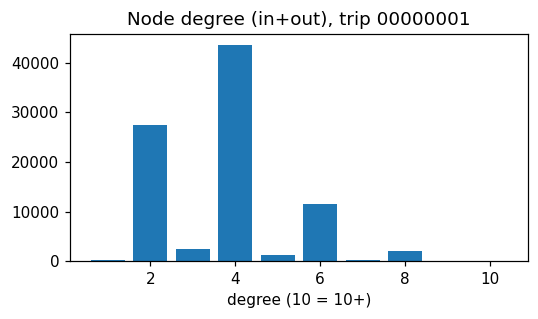

In [9]:
# node degree distribution for one example trip
_, nodes_e, arcs_e, _ = load_trip("train", stats.trip.iloc[0])
deg = np.bincount(arcs_e.u, minlength=len(nodes_e)) + np.bincount(arcs_e.v, minlength=len(nodes_e))
vals, cnt = np.unique(np.clip(deg, 0, 10), return_counts=True)
plt.figure(figsize=(5, 3)); plt.bar(vals, cnt); plt.title(f"Node degree (in+out), trip {stats.trip.iloc[0]}"); plt.xlabel("degree (10 = 10+)")
plt.tight_layout(); plt.savefig(f"{OUT}/degree_example.png"); plt.show()

Most arcs (about 85%) come with a reverse twin: two-way streets are stored as **two directed arcs**. A nearest-arc rule therefore cannot tell the direction; **heading** is essential. Isolated nodes and small disconnected components exist (networks are clipped around each trip), which the HMM will have to tolerate.

## 8. Reference route structure

In [10]:
display(stats.groupby("split")[["n_route_arcs", "route_breaks", "route_unique_frac"]].describe().T.round(3))
print("trips with any break between consecutive route arcs:", stats[stats.route_breaks > 0][["split", "trip", "route_breaks", "n_route_arcs"]].to_dict("records"))

split                    student_test     train
n_route_arcs      count        10.000    80.000
                  mean        347.700   391.700
                  std         359.574   361.165
                  min          95.000    59.000
                  25%         153.500   168.250
                  50%         250.000   280.000
                  75%         357.750   480.500
                  max        1323.000  2266.000
route_breaks      count        10.000    80.000
                  mean          0.100     0.162
                  std           0.316     0.489
                  min           0.000     0.000
                  25%           0.000     0.000
                  50%           0.000     0.000
                  75%           0.000     0.000
                  max           1.000     3.000
route_unique_frac count        10.000    80.000
                  mean          0.981     0.998
                  std           0.061     0.010
                  min           0.807     0.938
                  25%           1.000     1.000
                  50%           1.000     1.000
                  75%           1.000     1.000
                  max           1.000     1.000

trips with any break between consecutive route arcs: [{'split': 'train', 'trip': '00000002', 'route_breaks': 1, 'n_route_arcs': 262}, {'split': 'train', 'trip': '00000019', 'route_breaks': 3, 'n_route_arcs': 545}, {'split': 'train', 'trip': '00000033', 'route_breaks': 1, 'n_route_arcs': 169}, {'split': 'train', 'trip': '00000041', 'route_breaks': 1, 'n_route_arcs': 340}, {'split': 'train', 'trip': '00000042', 'route_breaks': 1, 'n_route_arcs': 1440}, {'split': 'train', 'trip': '00000069', 'route_breaks': 1, 'n_route_arcs': 467}, {'split': 'train', 'trip': '00000075', 'route_breaks': 2, 'n_route_arcs': 108}, {'split': 'train', 'trip': '00000080', 'route_breaks': 1, 'n_route_arcs': 139}, {'split': 'train', 'trip': '00000086', 'route_breaks': 1, 'n_route_arcs': 671}, {'split': 'train', 'trip': '00000089', 'route_breaks': 1, 'n_route_arcs': 265}, {'split': 'student_test', 'trip': '00000076', 'route_breaks': 1, 'n_route_arcs': 374}]


The route is an **ordered list of arc ids, one per traversed road segment, not one per GPS point**. Consecutive route arcs connect (`v_prev == u_next`) in almost every case, so the reference is a valid path. To get a label per GPS point we must **align** points to route arcs (done with a monotone dynamic programme in `pathsnap/labels.py`; see notebook 02).

## 9. Anomalies

In [11]:
summ = pd.read_csv("results/dataset_summary_train.csv", dtype={"trip_id": str})
st = stats.merge(summ[["trip_id", "median_align_dist_m"]], left_on="trip", right_on="trip_id", how="left")
anom = st[(st.gaps_over_30s > 0) | (st.jumps_over_70mps > 0) | (st.route_breaks > 0) | (st.median_align_dist_m > 50) | (st.n_points > 10000)]
anom = anom[["split", "trip", "n_points", "gaps_over_30s", "max_gap_s", "jumps_over_70mps", "route_breaks", "median_align_dist_m"]]
anom.to_csv(f"{OUT}/anomalies.csv", index=False)
anom.sort_values("median_align_dist_m", ascending=False)

,split,trip,n_points,gaps_over_30s,max_gap_s,jumps_over_70mps,route_breaks,median_align_dist_m
44,train,00000054,19313,2,79.0,0,0,140.008536
26,train,00000033,5844,0,3.0,1,1,122.383048
35,train,00000043,2322,2,230.0,2,0,11.003651
3,train,00000004,1064,2,51.0,0,0,8.552851
6,train,00000008,3093,0,2.0,1,0,7.793944
63,train,00000080,2510,2,59.0,0,1,7.385920
67,train,00000084,16031,4,312.0,0,0,6.583709
46,train,00000057,1645,0,13.0,1,0,6.142239
22,train,00000028,3565,4,196.0,0,0,6.127140
1,train,00000002,7243,10,160.0,0,1,5.765403


Trips **54** and **33** stand out: their GPS points are a median of 120–140 m away from the reference route (normal is about 5 m). The reference route does **not** describe the recorded track. Their labels would be wrong, so they are excluded from training (rule: median alignment distance > 50 m, decided on training data only). Trip 54 is also the 19k-point outlier.

## 10. Folium maps: GPS vs reference route vs road network

In [12]:
def eda_map(split, trip, out_html):
    track, nodes, arcs, route = load_trip(split, trip)
    m = folium.Map(tiles="OpenStreetMap")
    lo, hi = track[["lat", "lon"]].min() - 0.002, track[["lat", "lon"]].max() + 0.002
    inb = nodes.lat.between(lo.lat, hi.lat) & nodes.lon.between(lo.lon, hi.lon)
    keep = arcs[inb.values[arcs.u] & inb.values[arcs.v]]
    g_net = folium.FeatureGroup("Road network (clipped)")
    for u, v in keep.values[:1500]:
        folium.PolyLine([[nodes.lat[u], nodes.lon[u]], [nodes.lat[v], nodes.lon[v]]], color="#888", weight=1, opacity=.6).add_to(g_net)
    g_ref = folium.FeatureGroup("Reference route")
    for a in route.arc_id:
        u, v = arcs.u[a], arcs.v[a]
        folium.PolyLine([[nodes.lat[u], nodes.lon[u]], [nodes.lat[v], nodes.lon[v]]], color="green", weight=5, opacity=.8).add_to(g_ref)
    g_gps = folium.FeatureGroup("Raw GPS")
    for lat, lon in track[["lat", "lon"]].values[::4]:
        folium.CircleMarker([lat, lon], radius=2, color="blue", fill=True, opacity=.8).add_to(g_gps)
    for g in (g_net, g_ref, g_gps): g.add_to(m)
    folium.LayerControl().add_to(m)
    legend = """<div style="position: fixed; bottom: 30px; left: 30px; z-index: 9999; background: white; padding: 8px 10px; border: 1px solid #999; font-size: 13px;">
      <b>Trip {t}</b><br><span style="color:blue">&#9679;</span> Raw GPS<br><span style="color:green">&#9644;</span> Reference route<br><span style="color:#888">&#9644;</span> Road network</div>""".format(t=trip)
    m.get_root().html.add_child(folium.Element(legend))
    m.fit_bounds([[lo.lat, lo.lon], [hi.lat, hi.lon]])
    m.save(out_html)
    return m

ex_trip = stats[stats.split == "student_test"].sort_values("n_points").trip.iloc[2]
m = eda_map("student_test", ex_trip, f"results/maps/eda_trip_{ex_trip}.html")
print("saved results/maps/eda_trip_%s.html" % ex_trip)
m

saved results/maps/eda_trip_00000091.html


In [13]:
# the anomalous trip 33: GPS and reference route do not match
m33 = eda_map("train", "00000033", "results/maps/eda_trip_00000033_anomaly.html")
print("saved results/maps/eda_trip_00000033_anomaly.html")
m33

saved results/maps/eda_trip_00000033_anomaly.html


## 11. Data-quality notes (written to `eda/DATA_NOTES.md`)

In [14]:
dt_all = np.concatenate(list(dts_all.values()))
notes = f"""# Data notes (EDA on train + student_test; generated by eda/01_eda.ipynb)

## Organisation
- {int((stats.split=="train").sum())} train trips, {int((stats.split=="student_test").sum())} student_test trips; every trip folder has .track, .nodes, .arcs, .route.
- Each trip has its OWN local road network (nodes/arcs indexed by row number). .route lists arc ids in travel order (one per road segment, not per GPS point).

## Quality findings
- No NaNs, duplicated rows or invalid coordinates; timestamps sorted in all trips.
- Sampling: {np.mean(dt_all==1):.1%} of steps are exactly 1 s; {(dt_all>5).sum()} gaps > 5 s, {(dt_all>30).sum()} gaps > 30 s (max {dt_all.max():.0f} s).
- Points per trip: min {stats.n_points.min()}, median {int(stats.n_points.median())}, max {stats.n_points.max()} (trip 54).
- Trips are worldwide (lon {stats.lon_c.min():.0f}..{stats.lon_c.max():.0f}, lat {stats.lat_c.min():.0f}..{stats.lat_c.max():.0f}) -> distances must be metric per trip, never raw degrees.
- {stats.pct_arcs_with_reverse.mean():.0%} of arcs have a reverse twin -> direction (heading) is needed to pick the right arc.
- Networks contain small disconnected components and isolated nodes (clipped around each trip).
- Reference routes are almost always continuous ({int(stats.route_breaks.sum())} breaks in total).
- Trips 54 and 33: reference route does not match the GPS track (median 140 m / 122 m away) -> excluded from training.

## Decisions
- Per-trip local equirectangular projection (metres) for all geometry.
- Candidates = arcs within 50 m of a GPS point (top-10); labels via monotone alignment of points to route arcs.
- Exclude training trips with median alignment distance > 50 m. Evaluator data never used.
"""
with open("eda/DATA_NOTES.md", "w", encoding="utf-8") as f: f.write(notes)
print(notes)

# Data notes (EDA on train + student_test; generated by eda/01_eda.ipynb)

## Organisation
- 80 train trips, 10 student_test trips; every trip folder has .track, .nodes, .arcs, .route.
- Each trip has its OWN local road network (nodes/arcs indexed by row number). .route lists arc ids in travel order (one per road segment, not per GPS point).

## Quality findings
- No NaNs, duplicated rows or invalid coordinates; timestamps sorted in all trips.
- Sampling: 96.7% of steps are exactly 1 s; 1260 gaps > 5 s, 135 gaps > 30 s (max 153064 s).
- Points per trip: min 262, median 1496, max 19313 (trip 54).
- Trips are worldwide (lon -100..137, lat -35..62) -> distances must be metric per trip, never raw degrees.
- 92% of arcs have a reverse twin -> direction (heading) is needed to pick the right arc.
- Networks contain small disconnected components and isolated nodes (clipped around each trip).
- Reference routes are almost always continuous (14 breaks in total).
- Trips 54 and 33: reference rout